In [ ]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np, time, random, os, json

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

CUDA available: True
Device: cuda
GPU: Tesla T4


In [ ]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=transform)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=transform)

gen = torch.Generator().manual_seed(SEED)
train_set, val_set = random_split(full_train, [45000, 5000], generator=gen)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=128, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=128, shuffle=False, num_workers=2)

classes = full_train.classes
print(classes)
print(len(train_set), len(val_set), len(test_set))

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
45000 5000 10000


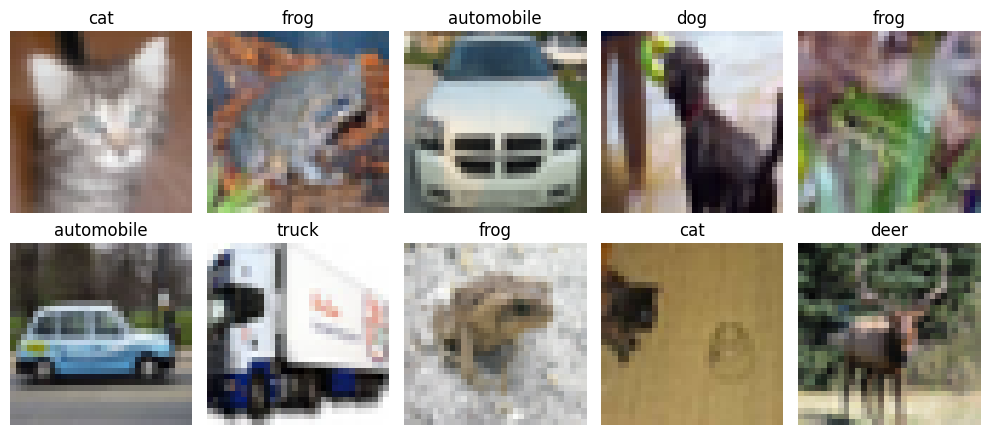

In [ ]:
imgs, labels = next(iter(train_loader))
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3,1,1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3,1,1)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    img = (imgs[i] * std + mean).permute(1, 2, 0).clamp(0, 1)
    ax.imshow(img); ax.set_title(classes[labels[i]]); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/sample_images.png", dpi=150)
plt.show()

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, epochs=10, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    start = time.time()
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc"], [tl, vl, ta, va]):
            hist[k].append(v)
        print(f"Epoch {ep+1}/{epochs} | train acc {ta:.3f} | val acc {va:.3f} | val loss {vl:.3f}")
    hist["time"] = time.time() - start
    return hist

model = SmallCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Parameters:", n_params)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=2048, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Parameters: 620362


In [ ]:
hist_cnn = fit(model, epochs=10)
print(f"Training time: {hist_cnn['time']:.1f}s")

Epoch 1/10 | train acc 0.469 | val acc 0.567 | val loss 1.202
Epoch 2/10 | train acc 0.615 | val acc 0.647 | val loss 0.988
Epoch 3/10 | train acc 0.684 | val acc 0.694 | val loss 0.867
Epoch 4/10 | train acc 0.725 | val acc 0.738 | val loss 0.758
Epoch 5/10 | train acc 0.757 | val acc 0.734 | val loss 0.759
Epoch 6/10 | train acc 0.783 | val acc 0.755 | val loss 0.695
Epoch 7/10 | train acc 0.805 | val acc 0.763 | val loss 0.684
Epoch 8/10 | train acc 0.821 | val acc 0.778 | val loss 0.653
Epoch 9/10 | train acc 0.840 | val acc 0.772 | val loss 0.676
Epoch 10/10 | train acc 0.857 | val acc 0.769 | val loss 0.718
Training time: 119.2s


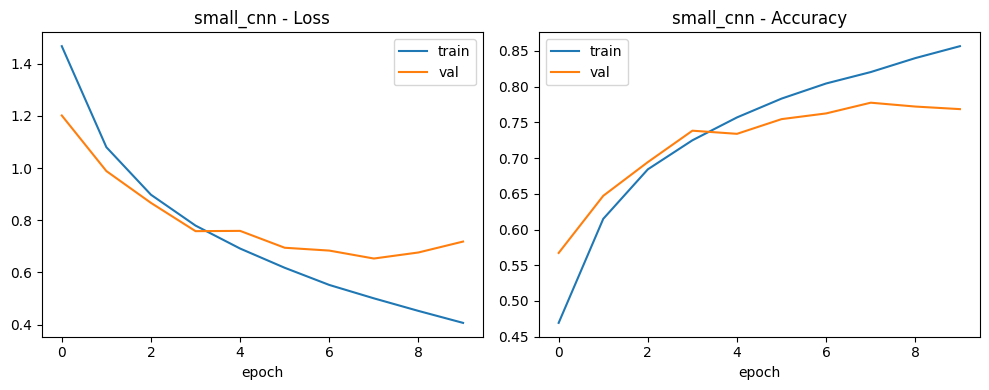

Small CNN Test Accuracy: 0.7700
{'small_cnn': {'params': 620362, 'train_time_s': 119.18109083175659, 'best_val_acc': 0.7776, 'test_acc': 0.77}}


In [ ]:
def plot_hist(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
    ax[0].set_title(f"{name} - Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["val_acc"], label="val")
    ax[1].set_title(f"{name} - Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}_curves.png", dpi=150); plt.show()

plot_hist(hist_cnn, "small_cnn")

test_loss, test_acc = run_epoch(model, test_loader, nn.CrossEntropyLoss())
print(f"Small CNN Test Accuracy: {test_acc:.4f}")

torch.save(model.state_dict(), f"{OUT}/small_cnn.pth")

results = {"small_cnn": {"params": n_params, "train_time_s": hist_cnn["time"],
                         "best_val_acc": max(hist_cnn["val_acc"]), "test_acc": test_acc}}
json.dump(results, open(f"{OUT}/results.json", "w"), indent=2)
print(results)

In [ ]:
from google.colab import files
os.system("zip -r outputs.zip outputs")
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

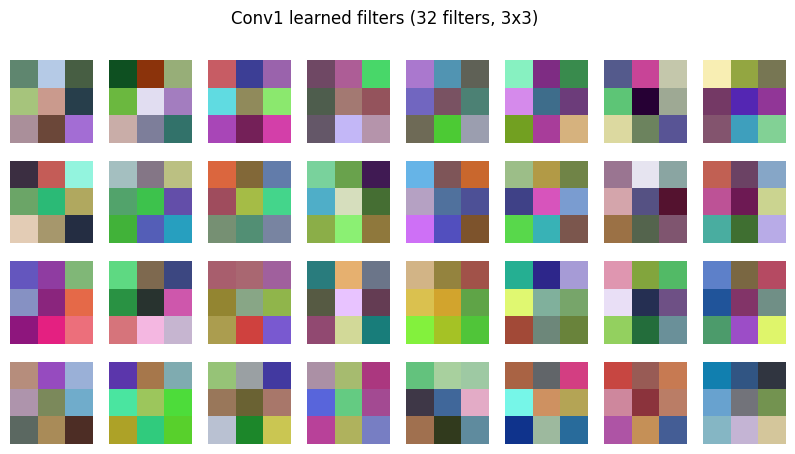

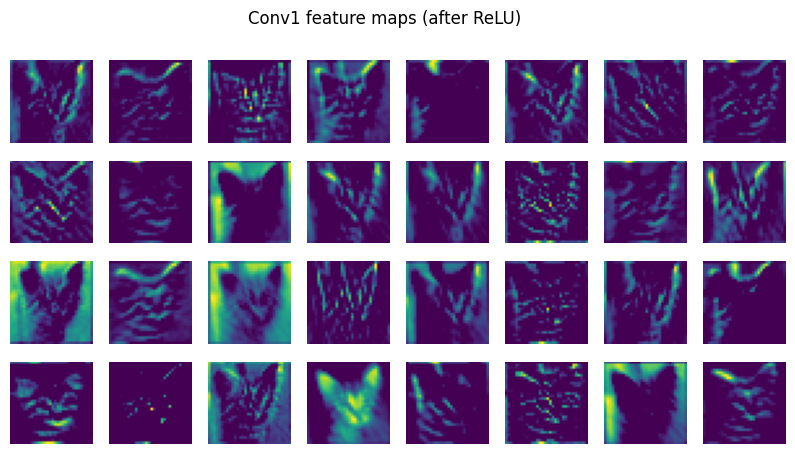

In [ ]:
w = model.features[0].weight.data.cpu()          # shape: 32 x 3 x 3 x 3
w = (w - w.min()) / (w.max() - w.min())          # 0-1 scale

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i].permute(1, 2, 0)); ax.axis("off")
plt.suptitle("Conv1 learned filters (32 filters, 3x3)")
plt.savefig(f"{OUT}/conv1_filters.png", dpi=150); plt.show()

# Feature maps of one image after Conv1
x = imgs[0:1].to(device)
with torch.no_grad():
    fmap = torch.relu(model.features[0](x)).cpu()[0]   # 32 x 32 x 32

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap[i], cmap="viridis"); ax.axis("off")
plt.suptitle("Conv1 feature maps (after ReLU)")
plt.savefig(f"{OUT}/conv1_feature_maps.png", dpi=150); plt.show()

In [ ]:
test_loss, test_acc = run_epoch(model, test_loader, nn.CrossEntropyLoss())
print(f"Small CNN Test Accuracy: {test_acc:.4f}")
print("Parameters:", n_params)

Small CNN Test Accuracy: 0.7700
Parameters: 620362


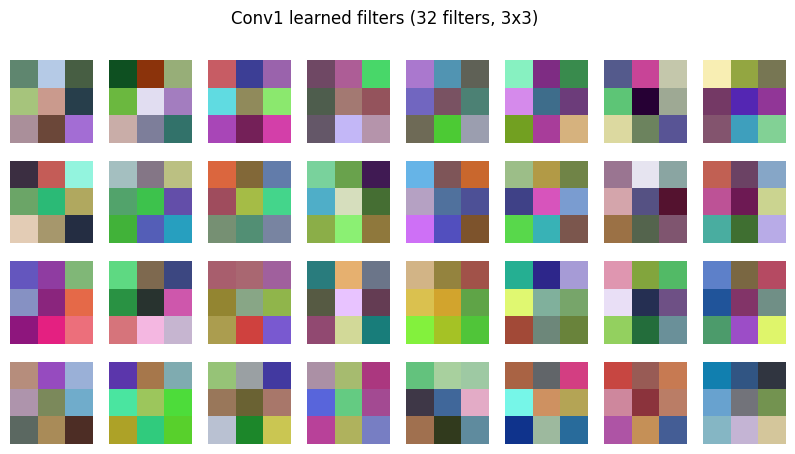

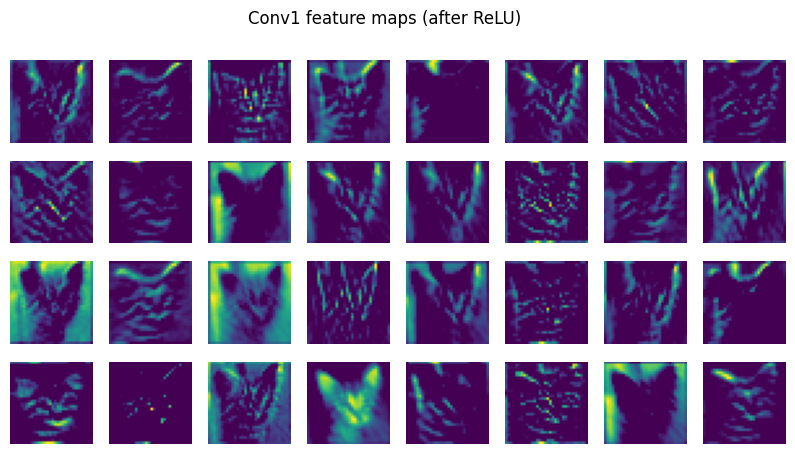

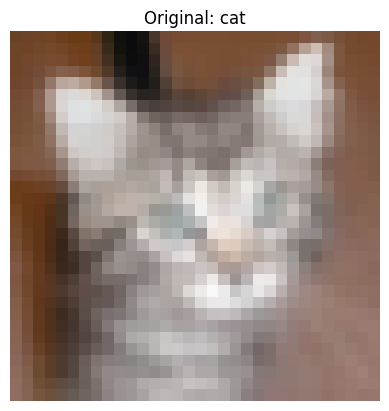

In [ ]:
# Part 1: Conv1 ke learned filters
w = model.features[0].weight.data.cpu()          # shape: 32 x 3 x 3 x 3
w = (w - w.min()) / (w.max() - w.min())          # 0-1 scale

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i].permute(1, 2, 0)); ax.axis("off")
plt.suptitle("Conv1 learned filters (32 filters, 3x3)")
plt.savefig(f"{OUT}/conv1_filters.png", dpi=150)
plt.show()

# Part 2: Ek image ke Conv1 feature maps
model.eval()
x = imgs[0:1].to(device)
with torch.no_grad():
    fmap = torch.relu(model.features[0](x)).cpu()[0]   # 32 x 32 x 32

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap[i], cmap="viridis"); ax.axis("off")
plt.suptitle("Conv1 feature maps (after ReLU)")
plt.savefig(f"{OUT}/conv1_feature_maps.png", dpi=150)
plt.show()

# Original image bhi save karo (report me comparison ke liye)
img = (imgs[0] * std + mean).permute(1, 2, 0).clamp(0, 1)
plt.imshow(img); plt.title(f"Original: {classes[labels[0]]}"); plt.axis("off")
plt.savefig(f"{OUT}/original_for_fmap.png", dpi=150)
plt.show()

In [ ]:
import torch.nn.functional as F
from torchvision import models

IMG_SIZE = 128

class Prep(nn.Module):
    """CIFAR-normalized 32x32 -> ImageNet-normalized IMG_SIZE x IMG_SIZE (on GPU)"""
    def __init__(self, size):
        super().__init__()
        self.size = size
        self.register_buffer("cm", torch.tensor([0.4914, 0.4822, 0.4465]).view(1,3,1,1))
        self.register_buffer("cs", torch.tensor([0.2470, 0.2435, 0.2616]).view(1,3,1,1))
        self.register_buffer("im", torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1))
        self.register_buffer("istd", torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1))
    def forward(self, x):
        x = x * self.cs + self.cm          # undo CIFAR normalization
        x = (x - self.im) / self.istd      # ImageNet normalization
        return F.interpolate(x, size=self.size, mode="bilinear", align_corners=False)

def build_resnet18(mode):
    torch.manual_seed(SEED)
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if mode == "feature_extraction":
        for p in m.parameters():
            p.requires_grad = False          # backbone freeze
    m.fc = nn.Linear(m.fc.in_features, 10)   # naya classifier (trainable)
    return nn.Sequential(Prep(IMG_SIZE), m).to(device)

# run_epoch dobara define (BatchNorm freeze option ke saath)
def run_epoch(model, loader, criterion, optimizer=None, freeze_bn=False):
    train = optimizer is not None
    model.train() if train else model.eval()
    if train and freeze_bn:
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d): mod.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit_tl(model, epochs, lr, freeze_bn=False):
    criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer, freeze_bn)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc"], [tl, vl, ta, va]):
            hist[k].append(v)
        print(f"Epoch {ep+1}/{epochs} | train acc {ta:.3f} | val acc {va:.3f} | val loss {vl:.3f}")
    hist["time"] = time.time() - start
    hist["peak_mem_mb"] = torch.cuda.max_memory_allocated() / 1e6
    return hist

EPOCHS = 5

In [ ]:
model_fe = build_resnet18("feature_extraction")
total = sum(p.numel() for p in model_fe.parameters())
trainable = sum(p.numel() for p in model_fe.parameters() if p.requires_grad)
print(f"Total params: {total:,} | Trainable: {trainable:,}")

hist_fe = fit_tl(model_fe, EPOCHS, lr=1e-3, freeze_bn=True)
_, test_acc_fe = run_epoch(model_fe, test_loader, nn.CrossEntropyLoss())
print(f"Time: {hist_fe['time']:.1f}s | Peak GPU mem: {hist_fe['peak_mem_mb']:.0f} MB | Test acc: {test_acc_fe:.4f}")
torch.save(model_fe.state_dict(), f"{OUT}/resnet18_feature_extraction.pth")

Total params: 11,181,642 | Trainable: 5,130
Epoch 1/5 | train acc 0.788 | val acc 0.837 | val loss 0.466
Epoch 2/5 | train acc 0.849 | val acc 0.851 | val loss 0.435
Epoch 3/5 | train acc 0.857 | val acc 0.855 | val loss 0.415
Epoch 4/5 | train acc 0.862 | val acc 0.858 | val loss 0.409
Epoch 5/5 | train acc 0.867 | val acc 0.858 | val loss 0.415
Time: 113.4s | Peak GPU mem: 656 MB | Test acc: 0.8542


In [ ]:
model_ft = build_resnet18("fine_tuning")
total_ft = sum(p.numel() for p in model_ft.parameters())
trainable_ft = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
print(f"Total params: {total_ft:,} | Trainable: {trainable_ft:,}")

hist_ft = fit_tl(model_ft, EPOCHS, lr=1e-4, freeze_bn=False)
_, test_acc_ft = run_epoch(model_ft, test_loader, nn.CrossEntropyLoss())
print(f"Time: {hist_ft['time']:.1f}s | Peak GPU mem: {hist_ft['peak_mem_mb']:.0f} MB | Test acc: {test_acc_ft:.4f}")
torch.save(model_ft.state_dict(), f"{OUT}/resnet18_fine_tuning.pth")

Total params: 11,181,642 | Trainable: 11,181,642
Epoch 1/5 | train acc 0.882 | val acc 0.931 | val loss 0.204
Epoch 2/5 | train acc 0.975 | val acc 0.935 | val loss 0.195
Epoch 3/5 | train acc 0.994 | val acc 0.942 | val loss 0.180
Epoch 4/5 | train acc 0.996 | val acc 0.938 | val loss 0.229
Epoch 5/5 | train acc 0.995 | val acc 0.928 | val loss 0.248
Time: 316.5s | Peak GPU mem: 1437 MB | Test acc: 0.9272


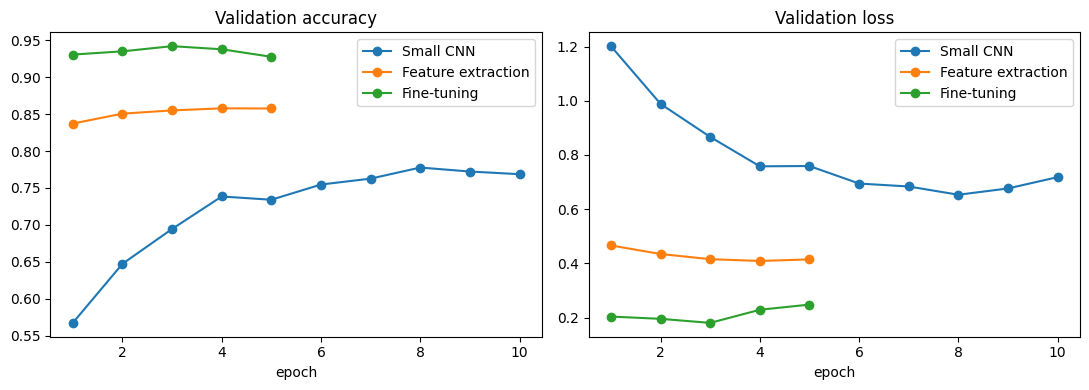

{
  "small_cnn": {
    "params": 620362,
    "train_time_s": 119.18109083175659,
    "best_val_acc": 0.7776,
    "test_acc": 0.77
  },
  "resnet18_feature_extraction": {
    "params_total": 11181642,
    "params_trainable": 5130,
    "train_time_s": 113.3594434261322,
    "peak_mem_mb": 655.706624,
    "best_val_acc": 0.8578,
    "test_acc": 0.8542
  },
  "resnet18_fine_tuning": {
    "params_total": 11181642,
    "params_trainable": 11181642,
    "train_time_s": 316.49793124198914,
    "peak_mem_mb": 1437.275648,
    "best_val_acc": 0.942,
    "test_acc": 0.9272
  }
}


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for h, name in [(hist_cnn, "Small CNN"), (hist_fe, "Feature extraction"), (hist_ft, "Fine-tuning")]:
    ax[0].plot(range(1, len(h["val_acc"])+1), h["val_acc"], marker="o", label=name)
    ax[1].plot(range(1, len(h["val_loss"])+1), h["val_loss"], marker="o", label=name)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/comparison_curves.png", dpi=150); plt.show()

# Results update
results = json.load(open(f"{OUT}/results.json"))
results["resnet18_feature_extraction"] = {"params_total": total, "params_trainable": trainable,
    "train_time_s": hist_fe["time"], "peak_mem_mb": hist_fe["peak_mem_mb"],
    "best_val_acc": max(hist_fe["val_acc"]), "test_acc": test_acc_fe}
results["resnet18_fine_tuning"] = {"params_total": total_ft, "params_trainable": trainable_ft,
    "train_time_s": hist_ft["time"], "peak_mem_mb": hist_ft["peak_mem_mb"],
    "best_val_acc": max(hist_ft["val_acc"]), "test_acc": test_acc_ft}
json.dump(results, open(f"{OUT}/results.json", "w"), indent=2)
print(json.dumps(results, indent=2))

In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
import matplotlib.patches as patches
from PIL import Image
import requests, io

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
det_model = fasterrcnn_resnet50_fpn(weights=weights, box_score_thresh=0.05).to(device).eval()
COCO_CLASSES = weights.meta["categories"]

det_params = sum(p.numel() for p in det_model.parameters())
print(f"Faster R-CNN params: {det_params:,}")

Faster R-CNN params: 41,755,286


In [ ]:
os.makedirs("det_images", exist_ok=True)
os.makedirs(f"{OUT}/detections", exist_ok=True)

urls = {
    "cats_couch":   "http://images.cocodataset.org/val2017/000000039769.jpg",
    "living_room":  "http://images.cocodataset.org/val2017/000000000139.jpg",
    "bear":         "http://images.cocodataset.org/val2017/000000000285.jpg",
    "stop_sign":    "http://images.cocodataset.org/val2017/000000000724.jpg",
    "bus_street":   "https://ultralytics.com/images/bus.jpg",
    "dog":          "https://github.com/pytorch/hub/raw/master/images/dog.jpg",
}

img_paths = []
for name, url in urls.items():
    try:
        r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
        r.raise_for_status()
        path = f"det_images/{name}.jpg"
        Image.open(io.BytesIO(r.content)).convert("RGB").save(path)
        img_paths.append(path)
        print("OK  ", name)
    except Exception as e:
        print("FAIL", name, "->", e)

print(f"{len(img_paths)} images ready")

OK   cats_couch
OK   living_room
OK   bear
OK   stop_sign
OK   bus_street
OK   dog
6 images ready


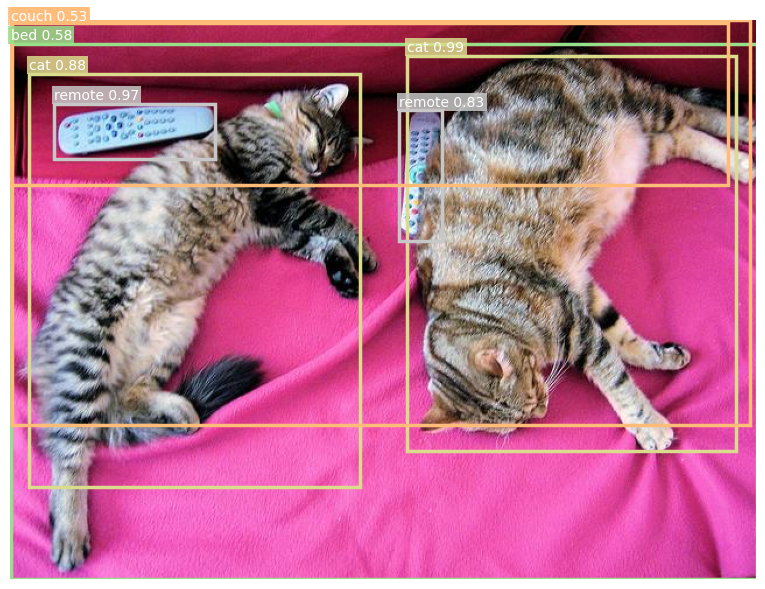

cats_couch -> [('cat', 0.993), ('remote', 0.974), ('cat', 0.882), ('remote', 0.829), ('bed', 0.578), ('couch', 0.568), ('couch', 0.53)]


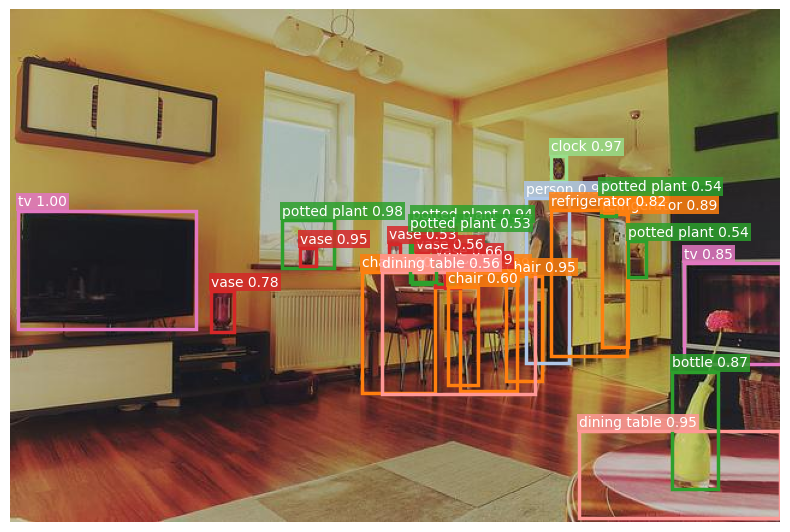

living_room -> [('chair', 0.998), ('tv', 0.996), ('chair', 0.989), ('potted plant', 0.98), ('clock', 0.971), ('dining table', 0.953), ('chair', 0.95), ('vase', 0.948), ('potted plant', 0.942), ('person', 0.907), ('refrigerator', 0.89), ('bottle', 0.874), ('tv', 0.85), ('refrigerator', 0.819), ('vase', 0.793), ('vase', 0.784), ('vase', 0.656), ('chair', 0.599), ('dining table', 0.565), ('vase', 0.557), ('potted plant', 0.544), ('potted plant', 0.537), ('vase', 0.533), ('potted plant', 0.532)]


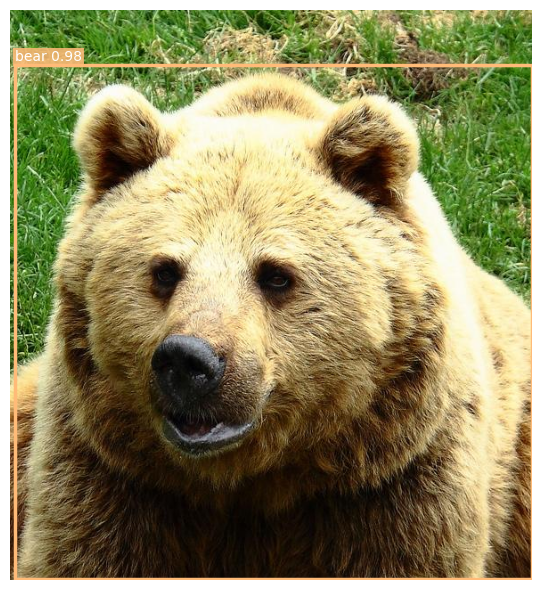

bear -> [('bear', 0.983)]


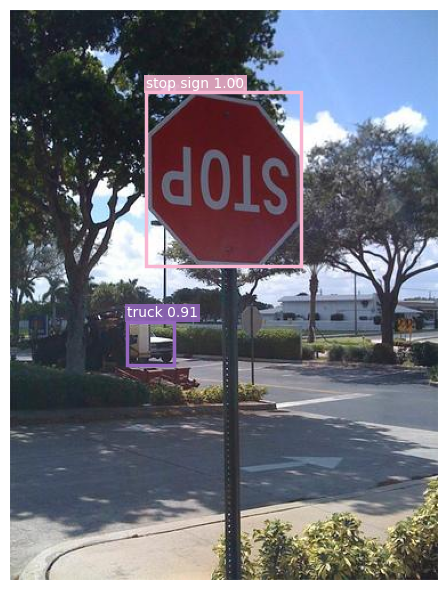

stop_sign -> [('stop sign', 1.0), ('truck', 0.91)]


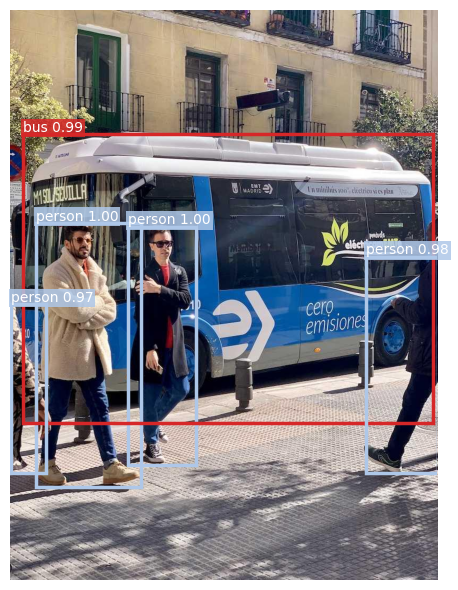

bus_street -> [('person', 0.999), ('person', 0.996), ('bus', 0.991), ('person', 0.983), ('person', 0.968)]


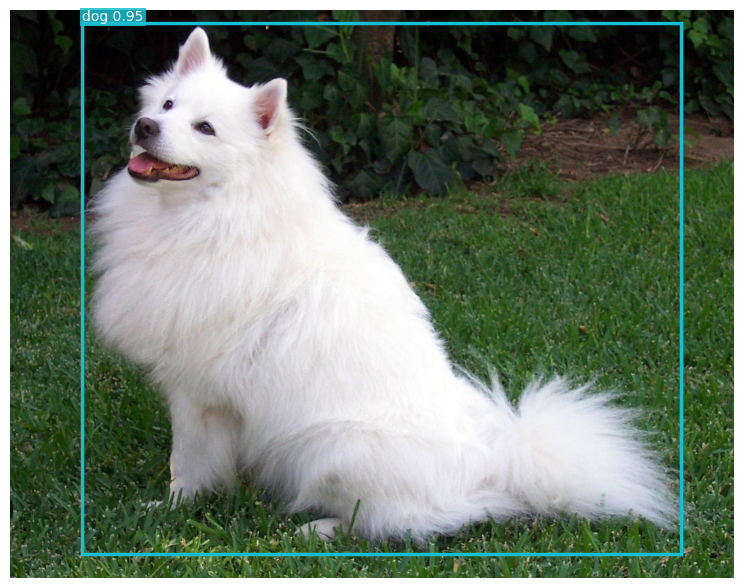

dog -> [('dog', 0.955)]


In [ ]:
import torchvision.transforms.functional as TF

THRESH = 0.5   # sirf wo detections jinki confidence >= 0.5

def detect(path):
    img = Image.open(path).convert("RGB")
    x = TF.to_tensor(img).to(device)
    with torch.no_grad():
        out = det_model([x])[0]
    keep = out["scores"] >= THRESH
    return img, out["boxes"][keep].cpu(), out["labels"][keep].cpu(), out["scores"][keep].cpu()

def draw(img, boxes, labels, scores, save_path):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img); ax.axis("off")
    cmap = plt.get_cmap("tab20")
    for b, l, s in zip(boxes, labels, scores):
        x1, y1, x2, y2 = b.tolist()
        color = cmap(int(l) % 20)
        ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=2.5))
        ax.text(x1, max(y1-4, 0), f"{COCO_CLASSES[int(l)]} {s:.2f}", color="white", fontsize=10,
                bbox=dict(facecolor=color, alpha=0.85, pad=1.5, edgecolor="none"))
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

det_summary = {}
for p in img_paths:
    name = os.path.splitext(os.path.basename(p))[0]
    img, boxes, labels, scores = detect(p)
    draw(img, boxes, labels, scores, f"{OUT}/detections/{name}_det.png")
    det_summary[name] = [(COCO_CLASSES[int(l)], round(float(s), 3)) for l, s in zip(labels, scores)]
    print(name, "->", det_summary[name])

In [ ]:
# Warm-up, phir inference time naapo
x = TF.to_tensor(Image.open(img_paths[0]).convert("RGB")).to(device)
with torch.no_grad():
    for _ in range(3): det_model([x])          # warm-up
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    N = 20
    for _ in range(N): det_model([x])
    torch.cuda.synchronize()
avg_ms = (time.time() - t0) / N * 1000
peak_mb = torch.cuda.max_memory_allocated() / 1e6

torch.save(det_model.state_dict(), "frcnn_tmp.pth")
size_mb = os.path.getsize("frcnn_tmp.pth") / 1e6

print(f"Inference: {avg_ms:.1f} ms/image (~{1000/avg_ms:.1f} FPS) | Peak GPU mem: {peak_mb:.0f} MB | Model size: {size_mb:.0f} MB")

results = json.load(open(f"{OUT}/results.json"))
results["faster_rcnn_resnet50_fpn"] = {"params": det_params, "inference_ms": avg_ms,
    "fps": 1000/avg_ms, "peak_mem_mb": peak_mb, "model_size_mb": size_mb,
    "conf_threshold": THRESH, "detections": det_summary}
json.dump(results, open(f"{OUT}/results.json", "w"), indent=2)

Inference: 169.0 ms/image (~5.9 FPS) | Peak GPU mem: 696 MB | Model size: 168 MB


In [ ]:
cnn = SmallCNN().to(device)
cnn.load_state_dict(torch.load(f"{OUT}/small_cnn.pth"))
_, test_acc_cnn = run_epoch(cnn, test_loader, nn.CrossEntropyLoss())
print(f"Small CNN Test Accuracy: {test_acc_cnn:.4f}")

Small CNN Test Accuracy: 0.7700


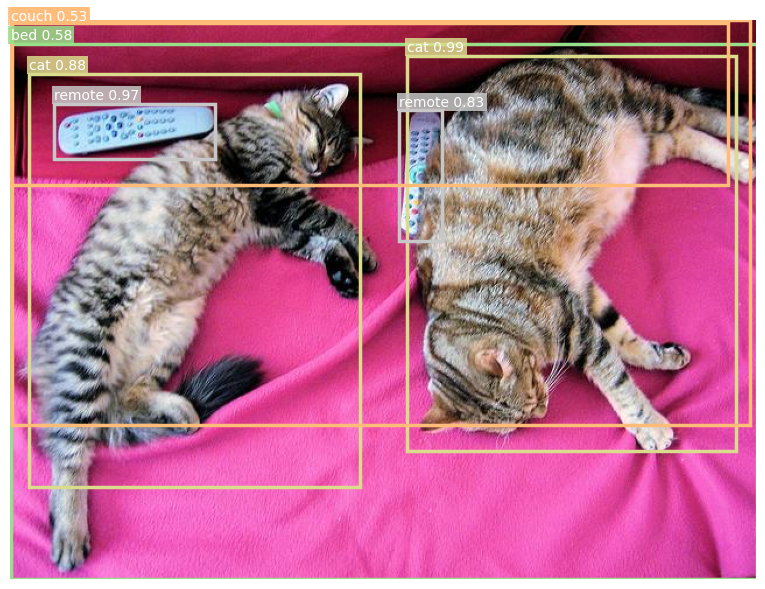

threshold 0.3: 7 detections


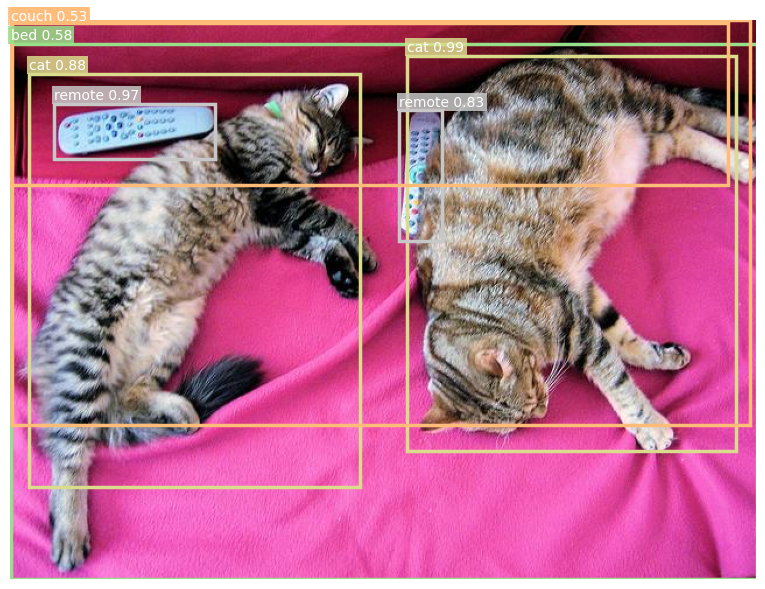

threshold 0.5: 7 detections


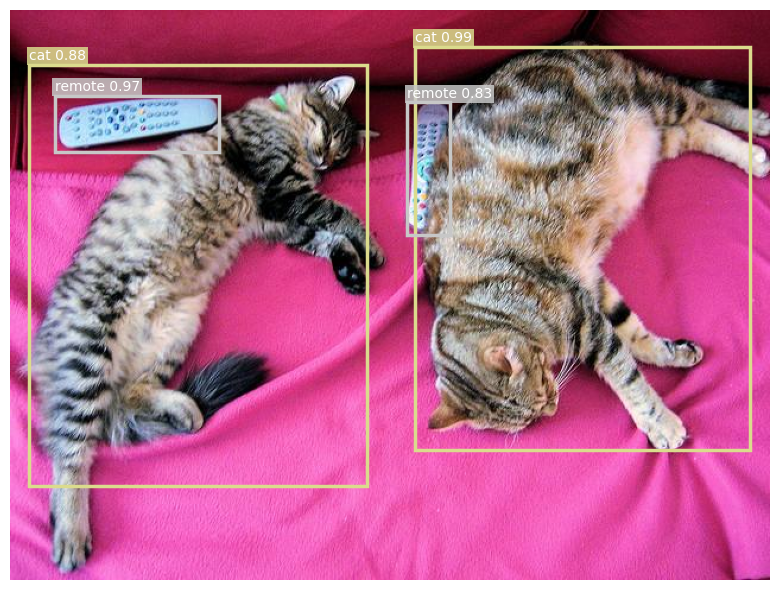

threshold 0.8: 4 detections


In [ ]:
for th in [0.3, 0.5, 0.8]:
    THRESH = th
    img, boxes, labels, scores = detect("det_images/cats_couch.jpg")
    draw(img, boxes, labels, scores, f"{OUT}/detections/cats_couch_th{th}.png")
    print(f"threshold {th}: {len(boxes)} detections")

In [ ]:
from google.colab import files
os.system("zip -r outputs.zip outputs")
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>